<a href="https://colab.research.google.com/github/3at0Hir0/3at0Hir0/blob/main/%E3%83%87%E3%83%BC%E3%82%BF%E3%82%B5%E3%82%A4%E3%82%A8%E3%83%B3%E3%82%B9%E6%BC%94%E7%BF%92_2_%E8%AC%9B%E7%BE%A9%E3%83%8E%E3%83%BC%E3%83%88%E3%83%96%E3%83%83%E3%82%AF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**第7回データサイエンス演習-2 欠損値、外れ値、可視化**


---

第7回データサイエンス演習パートにようこそ。\
前回の第6回講義と今回の第7回講義では、数値を予測する機械学習モデルである「**線形回帰**」を実装していきます。「データの理解」→「データの前処理」→「モデルの構築・評価」という一連の流れを通じて、データ分析の基礎から応用まで学んでいきます。\
本日第7回はレベル2とレベル3です。前回作成した機械学習モデルをレベルアップさせる手法を学びます。


#レベル2（★★☆）



---
さっそくレベル2に入ります。\
レベル2では、レベル1で学んだ手法をさらに実践的なデータに応用します。まずは、データを確認してその特性を理解し、得られた知見を基にデータの加工やモデルの構築に取り組みます。最後に、構築したモデルの評価を行い、全体を通じて応用力を深めていきます。

### 使用データセットについて
本演習では、モデル構築の学習用として以下の外部データセットを加工して使用しています。

- **データセット名**: Automobile Dataset
- **作成者/提供元**: Dr. Daqing Chen, UCI Machine Learning Repository
- **入手先**: https://archive.ics.uci.edu/dataset/10/automobile
- **ライセンス**: CC BY 4.0(クリエイティブ・コモンズ 表示 4.0 国際)

##2.1. データの理解

データの理解は、その後のデータの加工やモデルの構築を行う上で、非常に重要なステップです。今回は、自動車の外観や性能に関する約200件のデータを使用します。このデータは、前回より、理解するのに少し時間がかかるかもしれません。まずは数十件程度のデータを直接確認してみましょう。その後、各特徴量について詳しく調べていく流れになります。

では、「自動車価格のData」をダウンロードします。青字のリンク部分にマウスのカーソルを合わせてクリックし、リンク先に移動してください。移動したら、ダウンロードボタンを探してください。左クリックしてデータを保存します。\
[自動車価格のData.csv](https://drive.google.com/file/d/10gmRMbUVuDF8osJGdIop2b58PWDh7ezp/view?usp=drive_link)

データがダウンロードできたら、レベル1で扱ったファイルの保存場所にドラッグアンドドロップしてください。

無事にファイルをアップロードできたら、次は下のコードを使ってアップロードしたCSVファイルを読み込み、データフレームとして確認してみましょう。

In [ ]:
import pandas as pd

df = pd.read_csv('自動車価格のData.csv')

df

len関数でも、データフレームの行数を直接確認できます。

In [ ]:
len(df)

データフレームの head メソッドを使うと、先頭から指定した件数分のデータを表示できます。指定件数はカッコ内に書きます。末尾から特定の件数を確認したい場合は、tail メソッドを使います。たとえば、以下のコードではいずれもカッコ内に10と書いてあるので、headメソッドで先頭10件とtailメソッドで末尾10件を表示できます。

In [ ]:
df.head(10)

In [ ]:
df.tail(10)

カラム名を見てみると、『engine-size』、『city-mpg』、『curb-weight』、という特徴量を確認できます。それぞれ、「エンジンの大きさ」、「市街地走行時の燃費」、「車両の重量」という意味です。今回は、これらの量的データを使って価格を予測していきます。ここでよく見てみると、'price'の列に『NaN』と書かれている箇所があることが分かります。『NaN』は『Not a Number』の略で、数値データが存在しない、つまりデータが欠損していることを意味します。実際にファイルを直接開いてみると、NaNの部分が空欄になっているのを確認できます。

データを確認する際には、データの特徴を理解することも大切ですが、実務では 欠損値の確認 が必須です。欠損値とは、何らかの理由で値が記録されず、データが存在しない状態を指します。\
欠損値があるままでは正確な分析が難しくなるため、初めて扱うデータでは、まず欠損値が含まれているかを確認し、見つかった場合には適切な処理を行う必要があります。\
先ほど 'price'列には欠損値が含まれていましたが、他の特徴量にも欠損値があるかどうか、さらにその数がどれくらいあるのかはまだ分かりません。この情報を調べるには、データフレームの isnull メソッドを使います。このメソッドは、各データごとに欠損値があるかどうかを真偽値（True または False）で示したデータフレームを返します。

今回は以下のコードで、結果をdf_isnull に代入します。

In [ ]:
df_isnull = df.isnull()
df_isnull

現在表示されている範囲にはFalse、欠損値ではない、という結果が入っています。

そこで、データフレームの sum メソッドを使うことで、各列ごとに欠損値の数を合計できます。True は1、False は0として扱われるため、各列にどれだけ欠損値があるかを簡単に把握できます。

In [ ]:
df_isnull.sum()

'price'列にだけ欠損値があり、その数は4件であることが分かります。

今回は説明を分かりやすくするために、isnull メソッドの結果を一度 df_isnull に代入してから sum メソッドを使用しましたが、代入のステップを省略して、次のように連続して呼び出すことも可能です。

df に isnull メソッドを適用し、その結果に sum メソッドを続けて適用しています。

In [ ]:
df.isnull().sum()

最後に、説明変数である 'engine-size'、'curb-weight'、'city-mpg' と、目的変数である'price'の関係を可視化するために、**散布図**を作成してみます。可視化には、Pythonのライブラリである **matplotlib** を使用します。まずは、以下のコードで pyplot モジュールをインポートします。pltという省略名をつけるのが通例です。

In [ ]:
import matplotlib.pyplot as plt

散布図を描くには、pyplot の scatter 関数（plt.scatter）を使います。この関数の引数には、x軸にプロットするデータと、y軸にプロットするデータを指定します。さらに、xlabel と ylabel 関数でそれぞれの軸にラベルを設定し、show 関数でプロットを表示します。
今回は、x軸に engine-size、y軸に price をプロットするように指定します。


In [ ]:
plt.scatter(df['engine-size'], df['price'])
plt.xlabel('Engine-Size')
plt.ylabel('Price')
plt.show()

x軸の値が右に行くほど、y軸の値も上に行く傾向があることが分かります。つまり、'engine-size'が大きくなるほど、'price'も高くなる傾向にあることが分かりました。同様に'city-mpg'と'price'についても散布図を作成してみます。


In [ ]:
plt.scatter(df['city-mpg'], df['price'])
plt.xlabel('City-mpg')
plt.ylabel('Price')
plt.show()

今度は'city-mpg'が大きくなるほど、'price'は低くなる傾向にあることが分かりました。

最後に、'curb-weight'と'price'の散布図を作成します。

In [ ]:
plt.scatter(df['curb-weight'], df['price'])
plt.xlabel('Curb-weight')
plt.ylabel('Price')
plt.show()

'curb-weight'が大きくなるほど、'price'も高くなる傾向にあることが分かりました。

##2.2. データの前処理

次は、データの前処理をしていきます。

2.1のデータの理解の際に、一部に欠損値が含まれていることが分かりました。
まず、dropnaメソッドを使って、欠損値を1つでも含む行をデータフレームから削除してみます。

In [ ]:
df_drop = df.dropna()

ここで注意が必要なのは、df_drop は「欠損値を含む行を削除した新しいデータフレーム」であり、元のデータフレーム（df）は変更されないという点です。元のデータフレームには引き続き欠損値が残っており、isnull メソッドで確認することができます。

In [ ]:
df.head(10)

In [ ]:
df.isnull().sum()

データフレームの行数を比較して、どれだけ削除されたか確認してみましょう。

In [ ]:
print('削除前の行数', len(df))
print('削除後の行数', len(df_drop))

205から201と4つ違うので、4行が削除されたことが分かります。
これは2.1で確認した、price列に欠損値が4つあることと整合します。



次に、データを 説明変数 X と 目的変数 y に分けます。ここでは、'price'列を目的変数とし、それ以外の列を説明変数として扱います。\
レベル1で扱った列名を指定して抽出する方法を利用します。


In [ ]:
X = df_drop[['engine-size','city-mpg', 'curb-weight']]
y = df_drop['price']


Xの中身を確認しましょう。

In [ ]:
X

カラムに'price'がないことが分かります。

yの中身を確認しましょう。

In [ ]:
y

'price'だけが入っています。

##2.3. モデルの構築と評価

今回も、前回のレベル1と同様に**重回帰を用いた回帰モデル**を構築します。\
実際のデータ分析では、モデルを1つ作って終わりではありません。モデルの性能を評価し、その結果をもとに改善を繰り返すことで、より精度の高いモデルを目指します。

レベル1では、すべてのデータを使ってモデルを学習するところまでを行いました。しかし、この方法では、そのモデルがまだ見たことのないデータ（未知データ）に対してどの程度うまく予測できるかは分かりません。モデルを構築する本来の目的は、未知データを正確に予測できるようになることです。これを評価するための代表的な手法の一つが**ホールドアウト法** です。\
ホールドアウト法 では、すべてのデータを学習に使うのではなく、データを 学習用（訓練データ） と 評価用（テストデータ） に分けます。そして、モデルを訓練データで学習させ、テストデータでその予測精度を評価します。これは、「教科書の問題を丸暗記しただけでは本番の試験に通用するか分からない」という状況と同じです。学習に使わなかったデータ、つまり「初めて見る問題」を解いてみることで、本当の実力を評価することができます。


また、今回扱う自動車価格のDataは201件とデータ数が少ないため、どのデータを学習に使うかによってモデルの性能が大きく変わる可能性があります。このような場合、ホールドアウト法だけでは評価結果が不安定になることがあります。そこで、**交差検証**（クロスバリデーション）を組み合わせて活用します。交差検証では、データを複数回に分けて、学習とテストを繰り返すことで、モデルの性能をより安定して評価できるようになります。

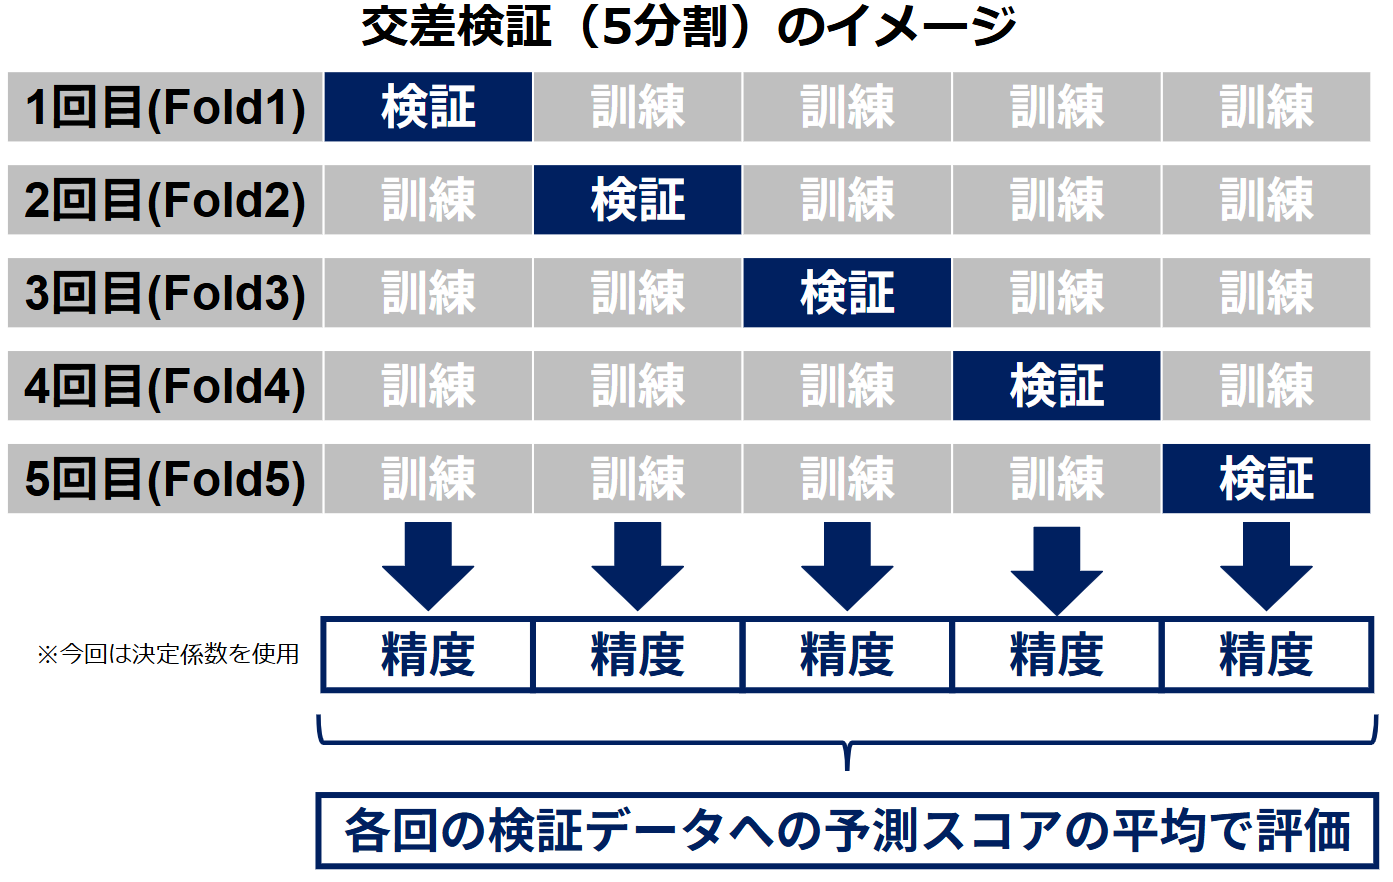

まずは、sklearnライブラリのmodel_selectionモジュールからKFoldクラスとcross_val_score関数をインポートします。\
KFold クラスは、「データをどのように分割するか」というルールを決めるためのものです。\
ここではn_splits引数でデータを5分割するように設定します。
shuffle引数をTrue に指定することで、データはまず ランダムに並び替え（シャッフル） され、その後で均等に5つのグループに分割されます。\
random_state=0 は、データをシャッフルする際の「乱数の種（シード）」を固定するための設定です。これを指定しておくことで、プログラムを何度実行しても、同じ順番でシャッフルされ、同じ分割結果を再現できるようになります。機械学習では「同じ条件で同じ結果を得られること」が重要なため、random_state を指定することはよく行われます。\
5分割されたデータでは、1つのグループがテストデータ、残り4つのグループが訓練データとして使用されます。最初は1つ目のグループをテストデータとして使用します。次は2つ目のグループをテストデータに、その次は3つ目のグループ、というように順番に切り替えていき、すべてのデータが一度はテストデータとして使われるようにします。

cross_val_score 関数で交差検証を実行します。この関数は、指定したモデルとデータに対して各分割ごとのスコアを計算し、それらをリストで返します。

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

model = LinearRegression()

kf = KFold(n_splits=5, shuffle=True, random_state=0)

scores = cross_val_score(model, X, y, cv=kf, scoring='r2')

たったこれだけで、モデルの学習と評価が完了します。

モデルの精度を測る指標として「**決定係数 𝑅²**」を使用しています。𝑅² はモデルの適合度を示し、 この値が 1 に近いほど、モデルの予測が実測値に近いことを意味します。𝑅²は以下の式で表されます。

\begin{eqnarray}
R^2 = 1 - \frac{\sum_{i=1}^n (y_i - f(x_i))^2}{\sum_{i=1}^n (y_i - \bar{y})^2}
\end{eqnarray}

ここで、

*   $n$はデータの総数（データフレームの行数）
*   $y_i$は$i$番目のデータの実測値
*   $f(x_i)$は$i$番目のデータに対するモデルの予測値
*   $\bar{y}$は目的変数$y$の平均値

を表しています。

右辺の二項目の分子の部分は、各データについて「実測値 と 予測値」の差を取り、その差を2乗して全部足し合わせたものです。これは、モデルの予測誤差の大きさを表しています。予測が正確であるほど、この値は小さくなります。\
一方、分母の部分は、各データについて「実測値 と 平均値」の差を2乗して足し合わせたものです。これは、「何も学習せず、いつも平均値だけを予測するモデル」の誤差の大きさだと考えることができます。

𝑅²は「いつも平均だけを予測するモデル」と比べて、どれだけ誤差を減らせているかを表す指標です。分子（モデルの誤差）が 0 に近づくほど、分数全体が小さくなり、1 −（小さい値）となるので、𝑅² は 1 に近づきます。

今回はデータを5分割したため、何分割目をテストデータに使ったか、それぞれの場合での決定係数が得られます。

In [ ]:
print('各分割における決定係数:', scores)
print('クロスバリデーションの平均決定係数:', scores.mean())

決定係数の平均値は0.762ということが分かりました。

決定係数には絶対的な基準が存在するわけではありません。分野やデータの特性によっても、どの程度の値が『高い』とみなされるかは異なります。そのため、1つのモデルの決定係数を見るだけでなく、複数のモデルの決定係数を比較することで精度を確認する ことが重要です。

今回の結果では決定係数が 0.762 という値を示しているので、現時点のモデルには一定の予測精度がありながらも、改善の余地はまだあると考えられます。


最後にもう一度、コードの各行が何をしているかおさらいします。

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score


model = LinearRegression()


kf = KFold(n_splits=5, shuffle=True, random_state=0)


scores = cross_val_score(model, X, y, cv=kf, scoring='r2')

1行目でscikit-learnからLinearRegressionモデルをインポートしています。\
2行目でsklearnライブラリのmodel_selectionモジュールからKFoldクラスとcross_val_score関数をインポートしています。\
model = でモデルのインスタンス化(実際に使える“モデルの実体”を作ること)をしています。\
kf = でデータをどのように分割するかというルールを決めましたが、まだ学習や評価は行われていません。\
scores = で、cross_val_score 関数によりホールドアウト法の考え方、訓練データとテストデータに分けて評価することを交差検証の内部で毎回実行し、5回の分割それぞれで計算された評価指標、今回は R² スコアをscoresに格納しています。

レベル2の学習内容は以上です。お疲れ様でした!\
レベル2では、レベル1と比べ、より実践的なデータを用いて、データの理解、前処理、モデルの構築・評価という一連のプロセスを学びました。特に、欠損値の扱いや散布図を用いたデータの可視化、交差検証を用いたモデルの評価方法について学びを進めました。レベル3ではデータの前処理を工夫してモデルの精度改善を目指します。

#レベル3（★★★）
---
レベル3では、散布図を使って外れ値を確認し、それを削除したデータでモデルを学習し、予測を行います。では、どのような値を外れ値と判断できるのでしょうか？外れ値の判断方法はいくつかありますが、今回はその中の1つを取り上げて解説します。順を追って確認していきましょう!

##3.1. データの前処理

レベル3の演習でも、レベル2で使用した「自動車価格のData」を扱います。まずはレベル2の復習を兼ねて、データの準備を進めましょう。\
青いリンクから「自動車価格のData.csv」をダウンロードし、所定の場所にアップロードしてください。レベル2で扱ったものが残っている場合は、アップロードをしなくて大丈夫です。そして、以下のコードを実行してデータフレームを読み込み、欠損値を含む行を削除します。



[自動車価格のData.csv](https://drive.google.com/file/d/10gmRMbUVuDF8osJGdIop2b58PWDh7ezp/view?usp=drive_link)

In [ ]:
import pandas as pd

df = pd.read_csv('自動車価格のData.csv')
df = df.dropna()

外れ値とは、他のデータと比べて極端に離れた値、外れてしまっている値のことを言います。これは測定時のミスや記録時のミスなどが原因で発生します。
外れ値を含むデータをそのまま分析すると、分析結果が外れ値に引っ張られて正しくなくなる場合があります。そのため、必要に応じて外れ値を確認し、削除や処理をすることが重要です。\
外れ値の判断にはいくつか方法がありますが、本ノートブックでは、散布図を用いて外れ値の除去に取り組みます。

レベル3では散布図から外れ値を判断します。\
初めに、'engine-size'と'price'の散布図を確認します。\
ここで注意が必要ですが、散布図を用いる場合、視覚的に外れ値を判断するため、具体的な数値などの定義がありません。ゆえに、人によって判断が分かれる場合があります。例えば、こちらの散布図で赤丸で囲まれている箇所に注目してください。確かに全体の傾向に対して少し異なっているようにも見えますが、許容範囲内にも見えます。今回は、外れ値とは判断せずに特に処理しないことにします。


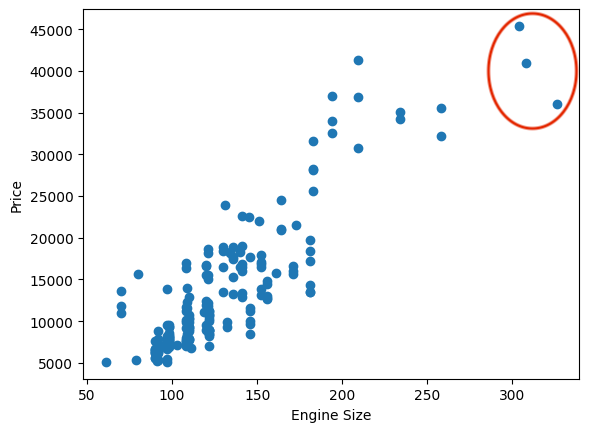

同様に'city-mpg'と'price'の散布図を確認します。


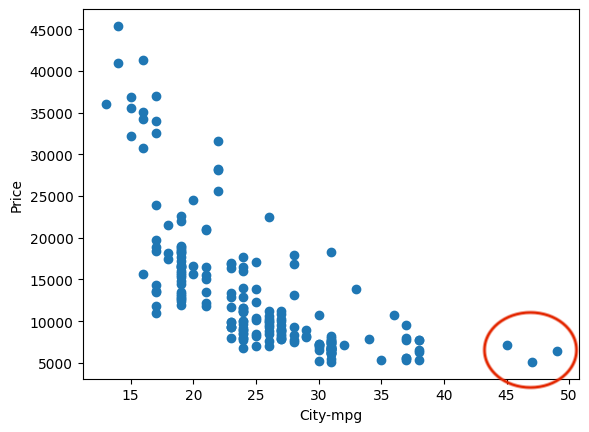

赤丸で囲まれているデータが全体と少し違った傾向に見えます。これらを外れ値とし、取り除きたいと思います。
散布図を読み取ると、いずれのデータもCity-mpgが40以上であることが分かります。外れ値以外のデータを残したいので、今回は、'city-mpg'列が40以下であるデータを残したいということになります。このような場合は、比較演算子を使うことで簡単に条件を設定できます。

まずは下のコードを見てください。\
このコードでは、df['city-mpg'] <= 40 （dfというデータフレームの'city-mpg'列が40以下である）という条件が、データフレームの各行に対して評価されます。
そして、is_under_40には、各行がこの条件を満たしているかどうかが真偽値で格納されます。条件に当てはまる場合はTrue、それ以外はFalseです。


In [ ]:
is_under_40 = df['city-mpg'] <= 40
is_under_40

結果から、先頭5つと末尾5つのデータにおいては'city-mpg' は40以下であるということが分かります。

次はこの真偽値の情報を用いて、Trueの行だけを取り出そうと思います。\
一般的に、データフレームが代入された変数名の後に続く[]の中に真偽値の情報を指定することで、Trueに該当する行だけを絞り込むことができます。

今回は変数の後の[ ]にis_under_40を入れます。\
そして、その結果をdf に再代入 します。

In [ ]:
df = df[is_under_40]

目的のデータが正しく削除されたかを確認しましょう。'city-mpg'と'price'の散布図を再度作成します。scatter 関数で引数にx軸にプロットするデータと、y軸にプロットするデータを指定します。さらに、xlabel と ylabel 関数でそれぞれの軸にラベルを設定し、show 関数でプロットを表示します。

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(df['city-mpg'], df['price'])
plt.xlabel('City-mpg')
plt.ylabel('Price')
plt.show()

先ほど赤丸で囲んでいた部分が無事に削除されており、全体としてデータの分布がよりまとまった形になったのが確認できます。

次に、curb-weightとpriceの散布図を確認してみます。こちらでも、赤丸で囲まれたデータが全体とは少し異なる傾向を持っているように見えます。
今回の外れ値は、'city-mpg'のときと比べて少し複雑な位置関係にあります。
こうした場合には、先ほどとは異なり、ひとまず外れ値だけを抽出してみるという方法を考えてみましょう。


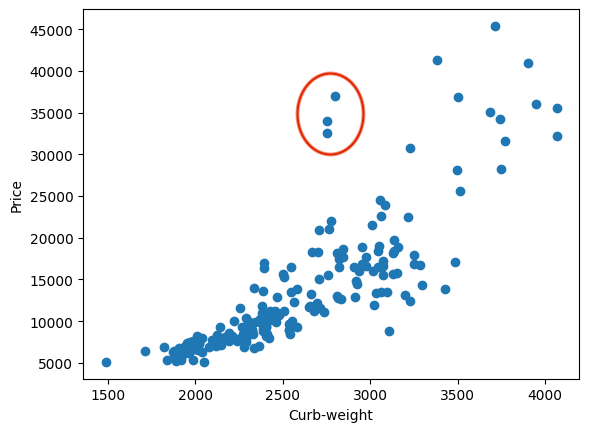

この3つの外れ値だけに該当する条件を考えると、'curb-weight'が3000以下であること、そしてなおかつ'price'が30000以上であることの2つの条件があると判断できます。\
このように、複数の条件を組み合わせてデータを絞りたい場合は以下のような記号が使えます。\
これらの記号は条件と条件の間に書くことで使います。


| 記号 | 意味 |
|------|------|
| ＆ | かつ |
| ｜| または |
| ～| でない |

今回は、「かつ」の条件を使うので、&で条件同士をつなぎます。まず、外れ値に該当するデータだけを取り出してみましょう。\
少し見づらいですが、コードの緑のカッコの中が一つ目の条件、この緑のカッコの中が二つ目の条件でこの2つを&でつないでいます。そして全体を[ ] の中に入れます。
先ほどは条件を一度is_under_40に代入してから、is_under_40を[ ] の中に入れたのですが、このように条件を直接書くことで一括で絞れます。


In [ ]:
df_out = df[(df['curb-weight'] <= 3000) & (df['price'] >= 30000)]

赤丸で囲んだ外れ値の3つが取り出せているか確認しましょう。

In [ ]:
df_out

指定した通り、'curb-weight'が3000以下かつpriceが30000以上という条件に該当するデータだけが無事取り出せています。

しかし、本来の目的は外れ値を排除することです。ここで使えるのが、「〇〇でない」を表す記号です。否定したい内容の前にチルダをつけましょう。

In [ ]:
df = df[~((df['curb-weight'] <= 3000) & (df['price'] >= 30000))]

これで外れ値以外のデータが抽出されているはずです。確認してみましょう。

In [ ]:
plt.scatter(df['curb-weight'], df['price'])
plt.xlabel('Curb-weight')
plt.ylabel('Price')
plt.show()

取り除くことができました。

これまでと同様に説明変数としてXには、'price'の列以外の列名を指定したデータフレームを代入します。yには目的変数の'price'の列だけを代入します。

In [ ]:
X = df[['engine-size','city-mpg', 'curb-weight']]
y = df['price']

##3.2. モデルの構築と評価

学習方法もレベル2と同様です。\
交差検証を用いて、モデルの精度を確かめましょう。


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

model = LinearRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=0)

scores = cross_val_score(model, X, y, cv=kf, scoring='r2')

print('各分割における決定係数:', scores)
print('クロスバリデーションの平均決定係数:', scores.mean())

今回の5つの決定係数の平均は0.800でした。レベル2では0.762だったので、外れ値の削除により少し精度が上がっていることが確認できました。

レベル3の学習内容は以上です。お疲れ様でした!\
レベル3では、散布図を用いて視覚的に外れ値を判断し、それを削除する方法を学びました。その結果、モデルの精度を向上させることができました。外れ値がモデル構築に与える影響を理解できたと思います。\
また、冒頭で特に散布図を用いた場合、外れ値の解釈は人によって異なる場合があることもお伝えしました。今回扱ったデータだけでなく、他のデータセットでも試行錯誤しながら外れ値の処理を実践してみてください。
